In [4]:
import pandas as pd

In [5]:
import seaborn as sns

In [6]:
import matplotlib.pyplot as plt
print(plt.title)

<function title at 0x0000022F6554BD70>


In [7]:
df=sns.load_dataset("taxis")

In [8]:
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [24]:
print(df.isnull().sum())

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [9]:
num_cols=df.select_dtypes(include="number").columns

In [10]:
for col in num_cols:
    df[col]=df[col].fillna(df[col].median())

In [11]:
cat_cols=df.select_dtypes(include=["object","category","str"]).columns

In [12]:
for col in cat_cols:
    if df[col].isnull().any():
        df[col]=df[col].fillna(df[col].mode()[0])
        

In [12]:
print(df.isnull().sum())

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


In [13]:
df["pickup"]=pd.to_datetime(df["pickup"])

In [14]:
df_sorted=df.sort_values("pickup")

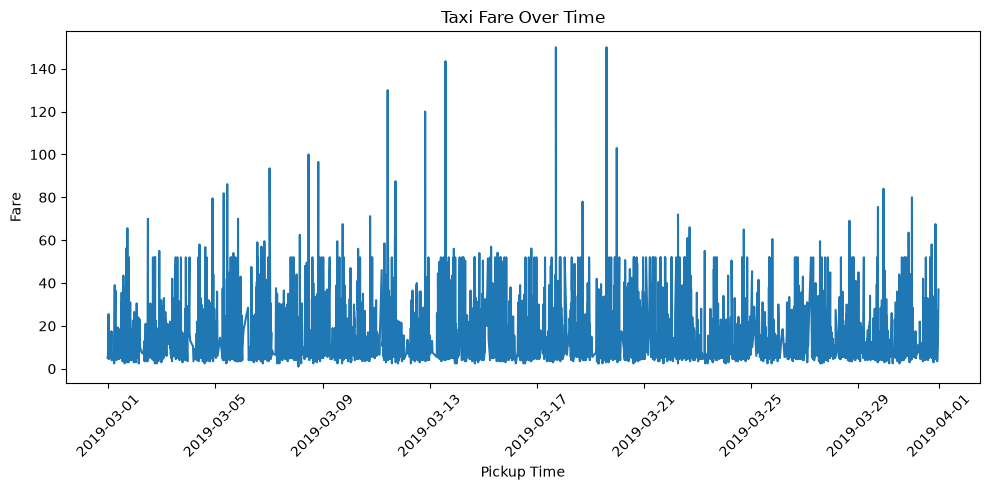

In [15]:
plt.figure(figsize=(10,5))
plt.plot(df_sorted["pickup"],df_sorted["fare"])
plt.title("Taxi Fare Over Time")
plt.xlabel("Pickup Time")
plt.ylabel("Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
borough_fare=df.groupby("pickup_borough",observed=True)["fare"].sum()

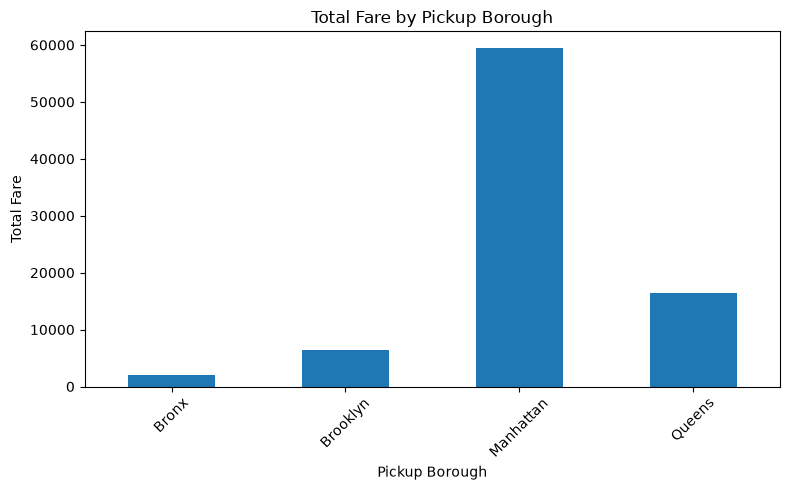

In [17]:
borough_fare.plot(kind="bar",figsize=(8,5))
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
payment_counts=df["payment"].value_counts()

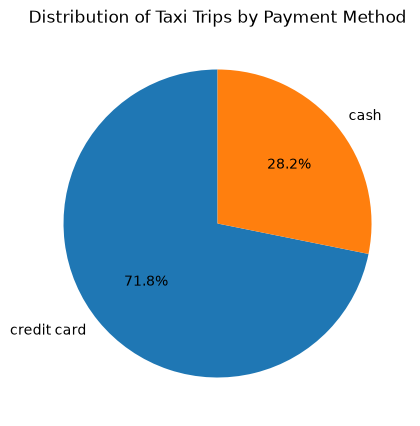

In [19]:
plt.figure(figsize=(5,5))
plt.pie(payment_counts,labels=payment_counts.index,
        autopct="%1.1f%%",startangle=90)
plt.title("Distribution of Taxi Trips by Payment Method")
plt.show()

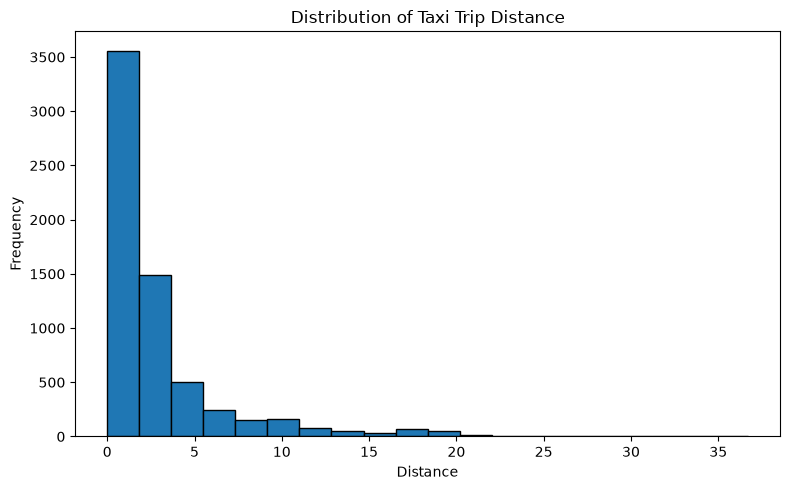

In [20]:
plt.figure(figsize=(8,5))
plt.hist(df["distance"],bins=20,edgecolor="black")
plt.title("Distribution of Taxi Trip Distance")
plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

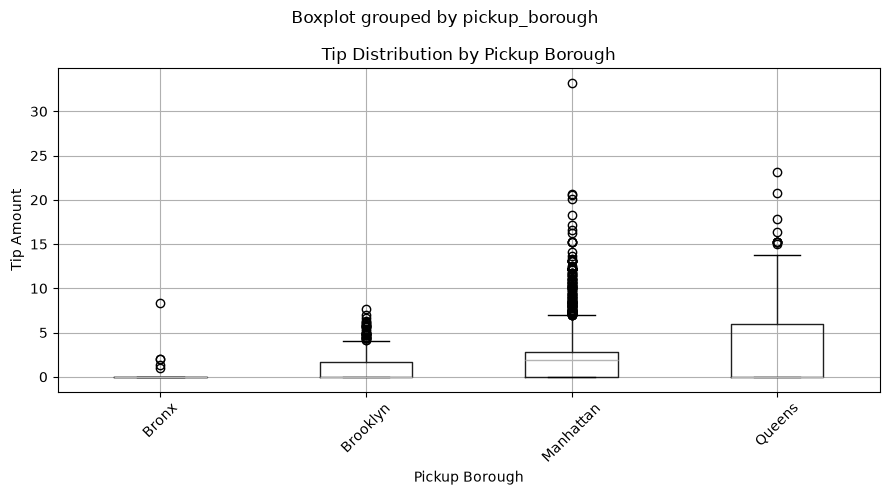

In [21]:
df.boxplot(column="tip",by="pickup_borough",figsize=(9,5))
plt.title("Tip Distribution by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

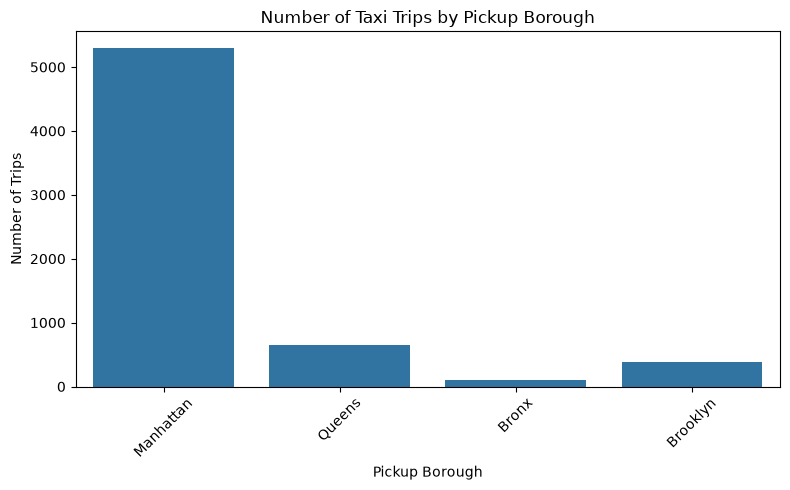

In [22]:
plt.figure(figsize=(8,5))
sns.countplot(data=df,x="pickup_borough")
plt.title("Number of Taxi Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

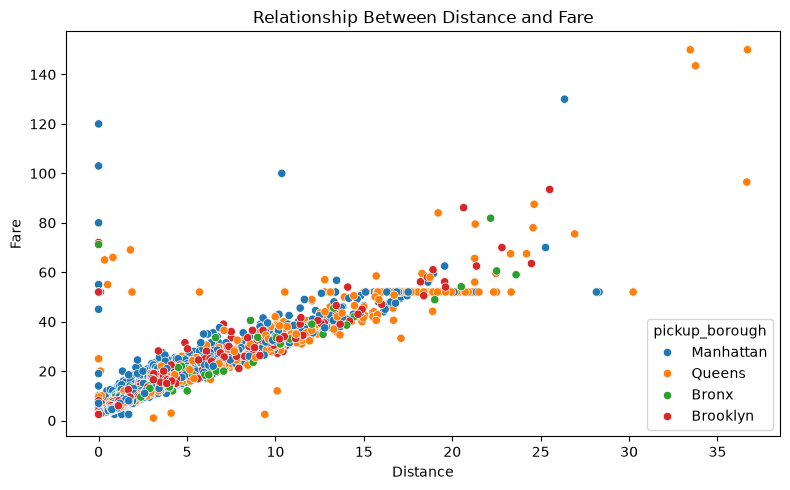

In [24]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,x="distance",y="fare",hue="pickup_borough")
plt.title("Relationship Between Distance and Fare")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()

In [25]:
numeric_cols=["distance","fare","tip","tolls","total"]
correlation=df[numeric_cols].corr()

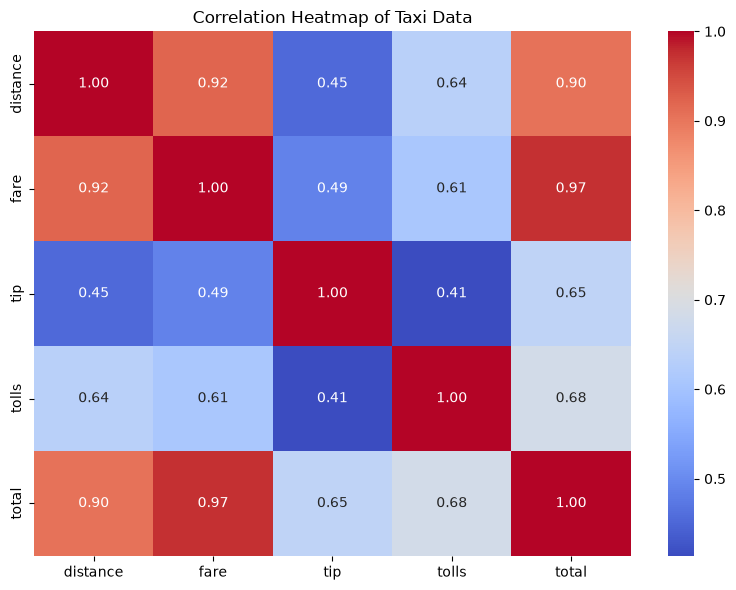

In [26]:
plt.figure(figsize=(8,6))
sns.heatmap(correlation,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Heatmap of Taxi Data")
plt.tight_layout()
plt.show()

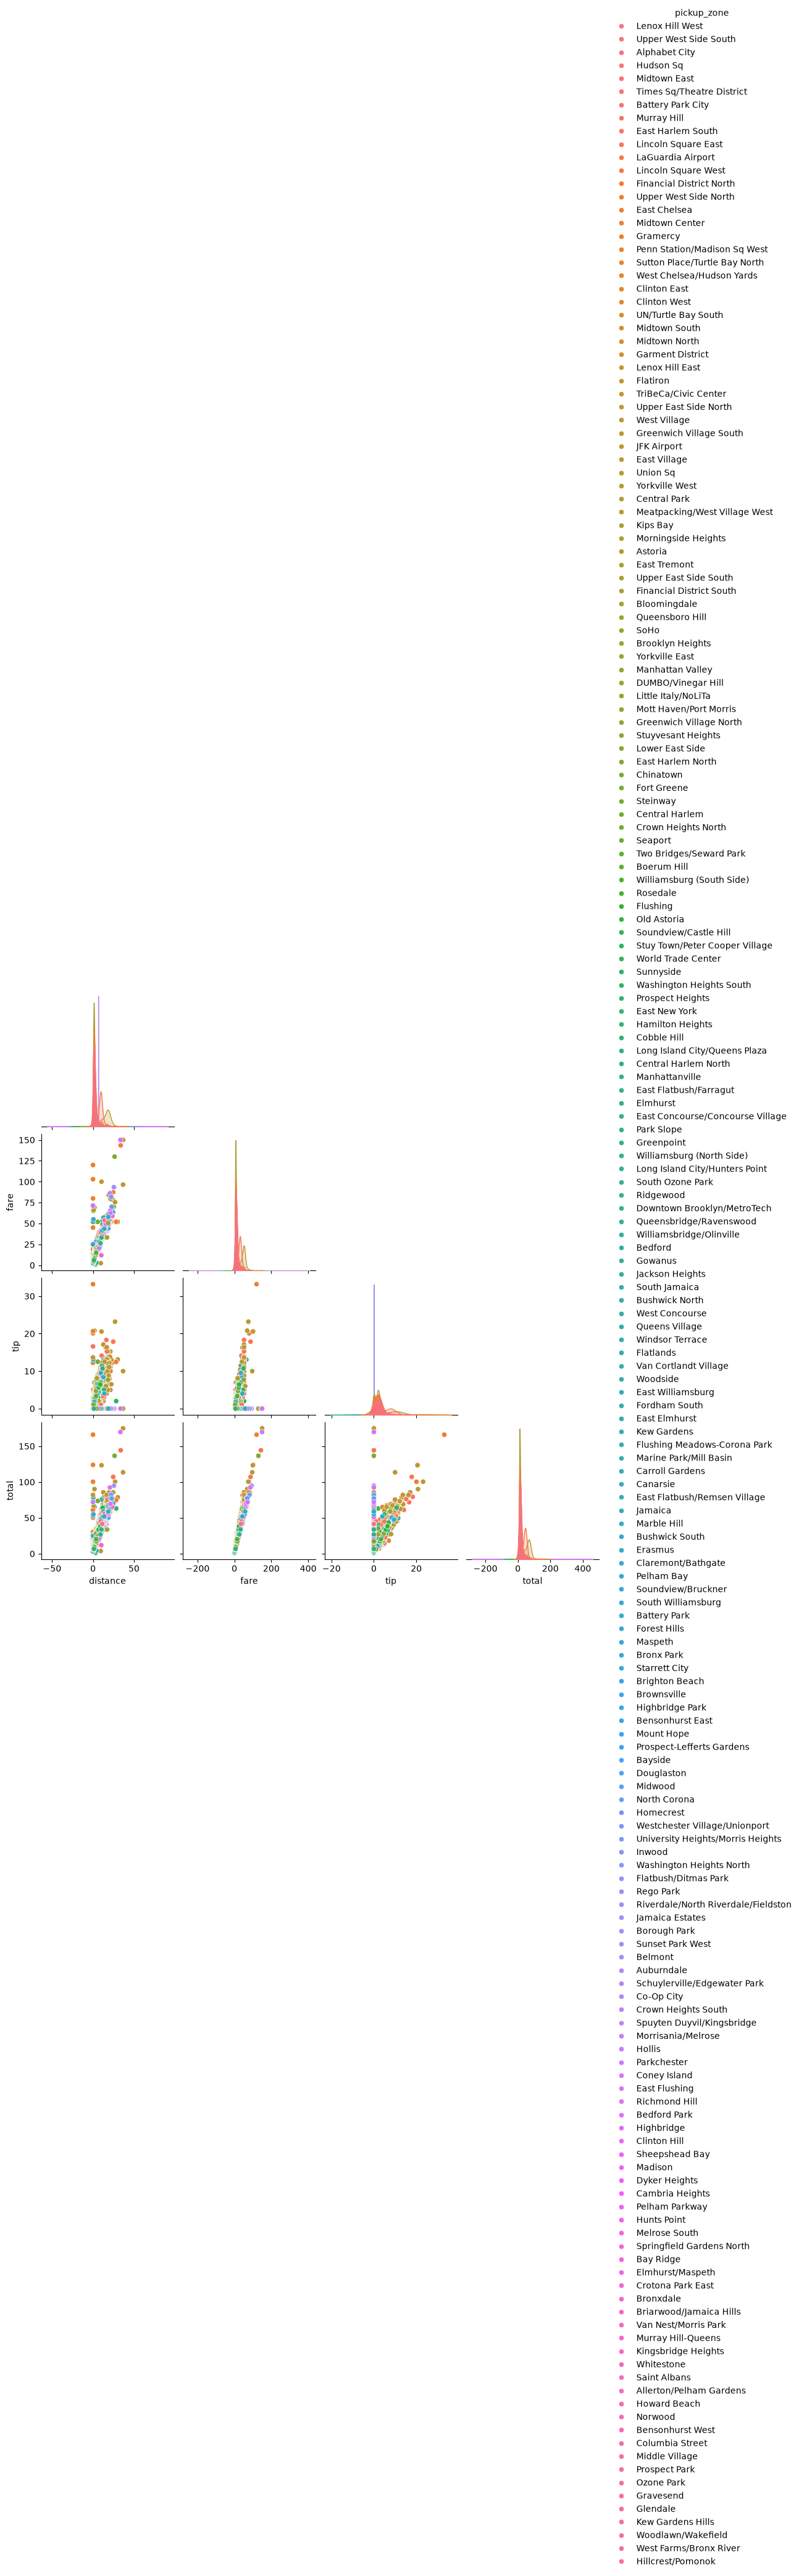

In [27]:
sns.pairplot(df,vars=["distance","fare","tip","total"],
             hue="pickup_zone",corner=True)
plt.show()

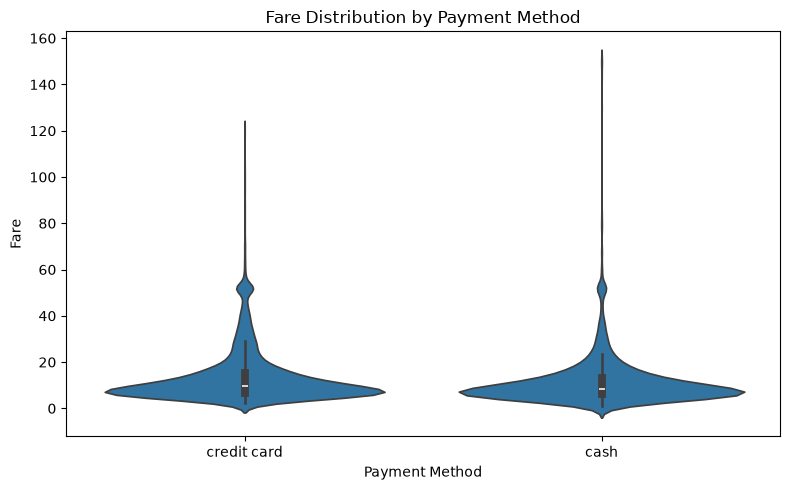

In [29]:
plt.figure(figsize=(8,5))
sns.violinplot(data=df,x="payment",y="fare")
plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()